# Why test forecast editing?

Pretrained time-series foundation models such as Chronos-2, TimesFM, and Moirai produce strong zero-shot forecasts out of the box—and then stop there. In practice, a statistical forecast is often just the starting draft: an analyst or planner knows about a capacity limit, a scheduled shutdown, or a calendar shift that never appeared in the historical series. Fine-tuning the foundation model on the fly isn't realistic, and hand-editing 50 future time steps is tedious. What if an evaluator only has to *score* a handful of proposed trajectories?

That setup, introduced in [Expert-Guided Forecast Editing for Time-Series Foundation Models](https://arxiv.org/abs/2607.19659v1), turns forecast revision into a tight-budget search problem. Pure exploitation (**Best-of-N quantile selection**) scores curves the model already assigns probability mass to. Pure exploration (**Direct CEM** or random search) perturbs the forecast in raw horizon space. **DEFT** aims for the middle ground: decompose quantile curves into trend and residual ($y = T + S$), evaluate balanced recombinations to reuse scores across components, and refine component-wise Gaussian proposals around the elites.

Two reasons make a local Chronos-2 test especially revealing. First, in the paper's own Table 3, **Chronos is the sharpest edge case**: Best-of-N quantile selection edges DEFT on ChronosBench MASE (`0.877` vs. `0.889`), likely because Chronos quantiles are already well calibrated. Second, implementing the algorithm from equations exposes every detail an overview glides past—context gaps in NN5, even-sized quantile grids, median-anchor counting, boundary padding, and single-elite variance collapse at small budgets.

This notebook runs the matched-budget comparison on 64 M4 monthly and 64 NN5 daily series, then integrates the full diagnostic follow-up—a [trace audit](followup-options-1-2/option1-findings.md), five [convention checks](followup-options-1-2/option2-findings.md), and a [variance-smoothing test](followup-option3-variance-smoothing/findings.md)—into a single narrative matching the [companion post](post.md).

## Setup

Use the paper-local `.venv`, source `environment.sh`, and select the `DEFT paper (.venv)` kernel. Offline replay (`DEFT_MODE=replay`) is the default: it verifies cached inputs, reconstructs every search trace from retained scalar scores, and blocks network calls or model weights. All original comparison code is inline below; the follow-up implementations live in `followup-options-1-2/` and `followup-option3-variance-smoothing/`.


In [1]:
import hashlib
import importlib.metadata
import json
import math
import os
import shutil
import socket
import sys
import time
from collections import Counter
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

class CFG:
    root = Path(os.environ.get("DEFT_RUN_ROOT", Path.cwd())).resolve()
    mode = os.environ.get("DEFT_MODE", "replay")
    run_id = os.environ.get("DEFT_RUN_ID", "measured-20261120")
    datasets = {"m4_monthly": {"horizon": 18, "season": 12}, "nn5": {"horizon": 56, "season": 7}}
    budgets = (8, 32, 128)
    seeds = (17, 29, 43)
    modes = ("rating5", "continuous")
    methods = ("best_quantile", "random_search", "direct_cem", "cem_prior", "pool_only", "deft")
    labels = {"best_quantile": "Best-of-N quantile", "random_search": "Random search",
              "direct_cem": "Direct CEM", "cem_prior": "CEM + prior", "pool_only": "Pool only", "deft": "DEFT"}
    context_length = 512
    development_n, evaluation_n = 8, 64
    model_revision = "29ec3766d36d6f73f0696f85560a422f50e8498c"
    data_revision = "eeecad0b82a8c237e212ce6f8d1abecb513e2cec"
    quantiles = (0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45,
                               0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99)
    elite_fraction = 0.2
    bootstrap_n, bootstrap_seed = 10_000, 20261119
    threads = 8
    figure_size, dpi = (10, 5.5), 160
    timezone = "Europe/Amsterdam"
    execution_timestamp = datetime.now(ZoneInfo(timezone))
    execution_date = execution_timestamp.strftime("%d%m")
    export_id = execution_timestamp.strftime("%Y%m%dT%H%M%S%f%z")
    memory_bytes, workspace_bytes = 24 * 1024**3, 15 * 1024**3

for key, relative in {"TMPDIR": "tmp", "XDG_CACHE_HOME": "cache/xdg", "MPLCONFIGDIR": "cache/matplotlib",
                      "HF_HOME": "cache/huggingface", "HF_HUB_CACHE": "cache/huggingface/hub",
                      "TORCH_HOME": "cache/torch", "IPYTHONDIR": "cache/ipython"}.items():
    directory = CFG.root / relative
    directory.mkdir(parents=True, exist_ok=True)
    os.environ[key] = str(directory)
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["MPLBACKEND"] = "Agg"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
from chronos import BaseChronosPipeline
from IPython.display import Image, display

torch.set_num_threads(CFG.threads)
plt.style.use("seaborn-v0_8")
plt.rcParams.update({"figure.figsize": CFG.figure_size, "figure.dpi": CFG.dpi, "font.size": 11})
audit_directory = CFG.root / "provenance"
audit_directory.mkdir(exist_ok=True)
runtime_audit = {"python":sys.version,"executable":sys.executable,"mode":CFG.mode,
                 "versions":{name:importlib.metadata.version(name) for name in
                             ("numpy","pandas","matplotlib","psutil","torch","chronos-forecasting","ipython")}}
(audit_directory / f"runtime-import-audit-{CFG.export_id}.json").write_text(json.dumps(runtime_audit,indent=2)+"\n")
if CFG.mode == "replay":
    def forbidden_external_call(*args, **kwargs):
        raise AssertionError("Network/model execution is forbidden during offline replay")
    socket.create_connection = forbidden_external_call
    socket.socket.connect = forbidden_external_call
    socket.socket.connect_ex = forbidden_external_call
    BaseChronosPipeline.from_pretrained = forbidden_external_call
print(f"Mode: {CFG.mode}; export timestamp: {CFG.execution_timestamp.isoformat()}; kernel: {sys.executable}")

Matplotlib is building the font cache; this may take a moment.


/Users/kbanachewicz/Documents/banan-lab/papers/deft-expert-guided-forecast-editing/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1120 09:20:07.113000 130 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Mode: replay; export timestamp: 2026-11-20T09:19:52.143690+01:00; kernel: /Users/kbanachewicz/Documents/banan-lab/papers/deft-expert-guided-forecast-editing/.venv/bin/python


The setup cell pins the frozen Chronos-2 revision (`float32` inference) and enforces offline replay guards; all search and metric arithmetic runs in `float64`.

## Utils

### Files and data preparation

Data preparation holds out the final horizon (`18` months for M4, `56` days for NN5) and keeps up to `512` preceding observations. Missing context values are carried forward strictly within the context window; any series with a missing initial value or incomplete target is excluded.


In [2]:
def digest_bytes(value):
    return hashlib.sha256(value).hexdigest()

def digest_file(path):
    return digest_bytes(Path(path).read_bytes())

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)

def check_resources():
    rss = psutil.Process().memory_info().rss
    if rss > CFG.memory_bytes:
        raise RuntimeError(f"Resident memory ceiling exceeded: {rss}")
    return rss

def implementation_hash():
    notebook = json.loads((CFG.root / "deft_forecast_editing.ipynb").read_text())
    tags = {"setup", "utils_data", "utils_editor", "utils_execution"}
    sources = ["".join(c["source"]) for c in notebook["cells"] if tags.intersection(c.get("metadata", {}).get("tags", []))]
    return digest_bytes("\n".join(sources).encode())

def validate_forecast(directory, member):
    path = directory / f"{member['key']}.npz"
    meta = json.loads(path.with_suffix(".json").read_text())
    assert meta["context_sha256"] == member["context_sha256"]
    assert meta["model_revision"] == CFG.model_revision and meta["horizon"] == member["horizon"]
    if meta["status"] == "complete":
        assert meta["prediction_sha256"] == digest_file(path)
        with np.load(path) as stored:
            assert stored["quantiles"].shape == (len(CFG.quantiles), member["horizon"])
            np.testing.assert_array_equal(stored["quantile_levels"], CFG.quantiles)
            assert np.isfinite(stored["quantiles"]).all()
    return meta

def feedback_value(loss, reference, mode, valid=True):
    if not valid:
        return -float("inf")
    return float(1 + math.floor(4 / (1 + loss/reference) + 0.5)) if mode == "rating5" else -float(loss)

def causal_context(raw):
    raw = np.asarray(raw, dtype=np.float64)
    if not len(raw) or not np.isfinite(raw[0]) or np.isinf(raw).any():
        raise ValueError("Context needs a finite first value and no infinities")
    mask = np.isnan(raw)
    indices = np.maximum.accumulate(np.where(~mask, np.arange(len(raw)), 0))
    filled = raw[indices].copy()
    longest = current = 0
    for missing in mask:
        current = current + 1 if missing else 0
        longest = max(longest, current)
    assert np.array_equal(filled[~mask], raw[~mask]) and np.isfinite(filled).all()
    return filled, mask, longest

def regular_dates(dates, dataset):
    dates = pd.DatetimeIndex(dates)
    if dates.hasnans:
        return False
    if dataset == "m4_monthly":
        ordinal = dates.to_period("M").asi8
        return bool(np.all(np.diff(ordinal) == 1) and
                    (dates.is_month_end.all() or dates.is_month_start.all() or len(set(dates.day)) == 1))
    ordinal = dates.to_numpy(dtype="datetime64[ns]").astype("int64")
    return bool(np.all(np.diff(ordinal) == 86_400_000_000_000))

def prepare_data(write=False):
    members, audits, inputs = [], [], {}
    sources = json.loads((CFG.root / "provenance/download-manifest.json").read_text())
    for entry in sources:
        if entry["kind"] == "data":
            assert entry["revision"] == CFG.data_revision
            assert digest_file(CFG.root / entry["path"]) == entry["sha256"]
    for dataset, settings in CFG.datasets.items():
        source = CFG.root / "data/source" / dataset / "train-00000-of-00001.parquet"
        frame = pd.read_parquet(source)
        if frame.id.isna().any() or not frame.id.is_unique:
            raise ValueError("Missing or duplicate source IDs")
        horizon, season = settings["horizon"], settings["season"]
        eligible = []
        for row in frame.itertuples(index=False):
            values = np.asarray(row.target, dtype=np.float64)
            begin = max(0, len(values) - horizon - CFG.context_length)
            raw, target = values[begin:-horizon], values[-horizon:]
            dates = pd.DatetimeIndex(row.timestamp)
            reason = "eligible"
            if len(values) != len(dates) or not regular_dates(dates[begin:], dataset):
                reason = "irregular_timestamps"
            elif len(raw) < max(3 * horizon, 3 * season):
                reason = "short_context"
            elif not len(raw) or not np.isfinite(raw[0]) or np.isinf(raw).any():
                reason = "invalid_context_start_or_infinity"
            elif not np.isfinite(target).all():
                reason = "nonfinite_target"
            if reason == "eligible":
                context, mask, longest = causal_context(raw)
                scale = float(np.mean(np.abs(context[season:] - context[:-season])))
                if not np.isfinite(scale) or scale <= 0:
                    reason = "zero_scale"
            audit = {"dataset": dataset, "id": str(row.id), "reason": reason}
            audits.append(audit)
            if reason != "eligible":
                continue
            key = f"{dataset}__{row.id}"
            member = {"key": key, "dataset": dataset, "id": str(row.id), "horizon": horizon,
                      "season": season, "context_n": len(context), "origin_index": len(values) - horizon,
                      "context_begin": begin, "target_begin": str(dates[-horizon]), "scale": scale,
                      "filled_n": int(mask.sum()), "filled_fraction": float(mask.mean()), "longest_fill_run": longest,
                      "context_sha256": digest_bytes(context.tobytes()),
                      "input_sha256": digest_bytes(raw.tobytes() + target.tobytes()),
                      "selection_hash": digest_bytes(f"deft-2607.19659-v1|{dataset}|{row.id}".encode())}
            eligible.append((member, raw.copy(), context, target.copy(), mask))
        eligible.sort(key=lambda item: item[0]["selection_hash"])
        if len(eligible) < CFG.development_n + CFG.evaluation_n:
            raise RuntimeError(f"Insufficient eligible {dataset}: {len(eligible)}")
        for rank, (member, raw, context, target, mask) in enumerate(eligible[:CFG.development_n + CFG.evaluation_n]):
            member.update({"rank": rank, "split": "development" if rank < CFG.development_n else "evaluation"})
            members.append(member)
            inputs[member["key"]] = {"raw_context": raw, "context": context, "target": target, "missing_mask": mask}
    manifest = {"members": members, "exclusions": dict(Counter((a["dataset"], a["reason"]) for a in audits))}
    # JSON objects cannot have tuple keys; keep the complete exclusion ledger in CSV.
    manifest["exclusions"] = {f"{k[0]}:{k[1]}": v for k, v in manifest["exclusions"].items()}
    if write:
        write_json(CFG.root / "data/cohort.json", manifest)
        pd.DataFrame(audits).to_csv(CFG.root / "data/eligibility.csv", index=False)
        directory = CFG.root / "data/selected"
        directory.mkdir(exist_ok=True)
        for key, arrays in inputs.items():
            np.savez_compressed(directory / f"{key}.npz", **arrays)
    else:
        retained = json.loads((CFG.root / "data/cohort.json").read_text())
        assert manifest == retained, "Cohort/preprocessing differs from frozen retained inputs"
        for key, arrays in inputs.items():
            with np.load(CFG.root / "data/selected" / f"{key}.npz") as stored:
                for name, array in arrays.items():
                    np.testing.assert_array_equal(array, stored[name])
    return members, inputs, pd.DataFrame(audits)

Series selection hashes IDs deterministically before any forecasting and writes a full eligibility ledger.

### Budgeted search

`search_editor` implements all six strategies behind a single scalar-only callback so every method pays the same query cost (including the initial median anchor). Notice in `allocation` and `elite_indices` that at `budget=32`, DEFT samples 2 candidates per component and CEM + prior samples 4 trajectories—keeping just **1 elite** per round (`ceil(0.2 * 2) = 1`, `ceil(0.2 * 4) = 1`), which triggers the variance collapse we examine later.


In [3]:
def allocation(budget):
    b = max(4, budget // 8)
    rounds = min(4, (budget // 2) // b)
    if budget <= 16:
        rounds = min(rounds, 1)
    return budget - b * rounds, b, rounds, b // 2

def quantile_pool(native, count):
    levels = np.linspace(0.01, 0.99, count)
    levels[np.flatnonzero(levels < 0.5)[-1]] = 0.5
    assert len(np.unique(levels)) == count and np.all(np.diff(levels) > 0)
    pool = np.stack([np.interp(levels, CFG.quantiles, native[:, h]) for h in range(native.shape[1])], axis=1)
    median_index = int(np.flatnonzero(levels == 0.5)[0])
    order = np.r_[median_index, np.delete(np.arange(count), median_index)]
    return pool, order

def moving_window(context, horizon):
    centered = context - context.mean()
    denominator = float(centered @ centered)
    end = min(horizon, len(context) // 2)
    acf = np.array([1.0] + [float(centered[lag:] @ centered[:-lag]) / denominator for lag in range(1, end + 2)])
    candidates = [lag for lag in range(2, end + 1)
                  if acf[lag] >= 0.2 and acf[lag] > acf[lag-1] and acf[lag] >= acf[lag+1]]
    window = min(candidates, key=lambda lag: (-acf[lag], lag)) if candidates else max(3, horizon // 4)
    return int(np.clip(window, 2, horizon))

def decompose(paths, window):
    left = (window - 1) // 2
    padded = np.pad(paths, ((0, 0), (left, window - 1 - left)), mode="edge")
    trend = np.stack([np.convolve(row, np.ones(window) / window, mode="valid") for row in padded])
    return trend, paths - trend

def balanced_pairs(count, queries, rng):
    assert count <= queries <= count * count
    pairs = [(i, i) for i in range(count)]
    for offset in rng.permutation(np.arange(1, count)):
        pairs.extend((int(i), int((i + offset) % count)) for i in rng.permutation(count))
    pairs = np.asarray(pairs[:queries], dtype=np.int64)
    assert len(np.unique(pairs, axis=0)) == queries
    for axis in range(2):
        degrees = np.bincount(pairs[:, axis], minlength=count)
        assert degrees.min() >= 1 and np.ptp(degrees) <= 1
    return pairs

def elite_indices(scores):
    count = max(1, math.ceil(CFG.elite_fraction * len(scores)))
    return np.argsort(-np.asarray(scores), kind="stable")[:count]

def proposal_floor(original_std, context):
    return np.maximum(np.maximum(0.01 * original_std, 1e-6 * context.std()), 1e-8)

def search_editor(method, native, context, budget, rng, score):
    """Editor receives no future/labels or hidden losses; only the scalar callback."""
    median = native[list(CFG.quantiles).index(0.5)].astype(np.float64)
    archive, observed, stages = [], [], []
    def ask(candidate):
        value = float(score(np.asarray(candidate, dtype=np.float64)))
        archive.append(np.asarray(candidate, dtype=np.float64).copy())
        observed.append(value)
        return value
    ask(median)
    pool, order = quantile_pool(native, budget)
    if method == "best_quantile":
        for index in order[1:]:
            ask(pool[index])
    elif method in ("random_search", "direct_cem", "cem_prior"):
        original_std = pool.std(axis=0)
        mu = median.copy()
        floor = proposal_floor(original_std, context)
        sigma = np.maximum(original_std, floor)
        if method == "random_search":
            for candidate in mu + rng.normal(size=(budget-1, len(mu))) * sigma:
                ask(candidate)
        else:
            if method == "cem_prior":
                seed_n, batch_n, rounds, _ = allocation(budget)
                seed_pool, seed_order = quantile_pool(native, seed_n)
                for index in seed_order[1:]:
                    ask(seed_pool[index])
                mu = np.asarray(archive)[elite_indices(observed)].mean(axis=0)
                original_std = seed_pool.std(axis=0)
                floor = proposal_floor(original_std, context)
                sigma = np.maximum(original_std, floor)
            else:
                batch_n = max(budget // 4, 2)
                rounds = math.ceil(budget / batch_n)
            for round_index in range(rounds):
                reuse_first = method == "direct_cem" and round_index == 0
                remaining = min(batch_n, budget - len(archive) + int(reuse_first))
                batch = np.vstack([mu, mu + rng.normal(size=(remaining-1, len(mu))) * sigma])
                values = np.array(([observed[0]] + [ask(y) for y in batch[1:]]) if reuse_first else [ask(y) for y in batch])
                stages.append({"kind": "raw", "round": round_index, "candidates": batch, "utilities": values, "mean": mu.copy(), "std": sigma.copy()})
                elites = batch[elite_indices(values)]
                mu, sigma = elites.mean(axis=0), np.maximum(elites.std(axis=0), floor)
    elif method in ("pool_only", "deft"):
        seed_n, batch_n, rounds, component_n = allocation(budget) if method == "deft" else (budget, 0, 0, 0)
        seed_pool, _ = quantile_pool(native, seed_n)
        window = moving_window(context, len(median))
        trend_pool, residual_pool = decompose(seed_pool, window)
        k = math.ceil(math.sqrt(seed_n))
        indices = np.floor(np.linspace(0, seed_n-1, k) + 0.5).astype(int)
        trends, residuals = trend_pool[indices], residual_pool[indices]
        std_t, std_s = trend_pool.std(axis=0), residual_pool.std(axis=0)
        floor_t, floor_s = proposal_floor(std_t, context), proposal_floor(std_s, context)
        for round_index in range(rounds + 1):
            queries = seed_n-1 if round_index == 0 else batch_n
            pairs = balanced_pairs(len(trends), queries, rng)
            values = np.array([ask(trends[i] + residuals[j]) for i, j in pairs])
            utility_t = np.full(len(trends), -np.inf)
            utility_s = np.full(len(residuals), -np.inf)
            np.maximum.at(utility_t, pairs[:, 0], values)
            np.maximum.at(utility_s, pairs[:, 1], values)
            stages.append({"kind": "components", "round": round_index, "window": window,
                           "trends": trends.copy(), "residuals": residuals.copy(), "pairs": pairs,
                           "utilities": values, "utility_trend": utility_t, "utility_residual": utility_s})
            elite_t, elite_s = trends[elite_indices(utility_t)], residuals[elite_indices(utility_s)]
            mu_t, mu_s = elite_t.mean(axis=0), elite_s.mean(axis=0)
            if round_index:
                std_t, std_s = elite_t.std(axis=0), elite_s.std(axis=0)
            if round_index < rounds:
                trends = mu_t + rng.normal(size=(component_n, len(median))) * np.maximum(std_t, floor_t)
                residuals = mu_s + rng.normal(size=(component_n, len(median))) * np.maximum(std_s, floor_s)
    else:
        raise ValueError(method)
    assert len(archive) == budget, (method, len(archive), budget)
    chosen = int(np.argmax(observed))
    return np.asarray(archive), np.asarray(observed), chosen, stages

For DEFT and Pool only, call `1` is the standalone median anchor and the remaining seed-stage queries evaluate balanced `T_i + S_j` recombinations.

### Scoring, inference and retained evidence


In [4]:
def metric_values(prediction, target, scale):
    error = np.asarray(prediction, dtype=np.float64) - target
    return {"mase": float(np.mean(np.abs(error)) / scale), "mae": float(np.mean(np.abs(error))), "mse": float(np.mean(error**2))}

def forecast_members(members, inputs, directory):
    directory.mkdir(parents=True, exist_ok=True)
    for entry in json.loads((CFG.root / "provenance/download-manifest.json").read_text()):
        if entry["kind"] == "model":
            assert entry["revision"] == CFG.model_revision
            assert digest_file(CFG.root / entry["path"]) == entry["sha256"]
    if all((directory / f"{m['key']}.json").exists() for m in members):
        records = [validate_forecast(directory,m) for m in members]
        write_json(directory / f"timing-{CFG.export_id}.json", {"load_seconds":0,"cache_only":True,"records":records})
        return records
    loading = time.monotonic()
    pipeline = BaseChronosPipeline.from_pretrained(str(CFG.root / "models/chronos-2"),
                                                   device_map="cpu", torch_dtype=torch.float32, local_files_only=True)
    load_seconds = time.monotonic() - loading
    records = []
    for member in members:
        check_resources()
        key = member["key"]
        destination = directory / f"{key}.npz"
        meta_path = directory / f"{key}.json"
        if meta_path.exists():
            meta = validate_forecast(directory, member)
            records.append(meta)
            continue
        started = datetime.now(ZoneInfo(CFG.timezone)).isoformat()
        timer = time.monotonic()
        meta = {"key": key, "context_sha256": member["context_sha256"], "model_revision": CFG.model_revision,
                "started": started, "horizon": member["horizon"], "status": "attempted", "seconds": None}
        write_json(meta_path, meta)
        try:
            model_input = torch.as_tensor(inputs[key]["context"].copy(), dtype=torch.float32)
            with torch.inference_mode():
                quantiles, _ = pipeline.predict_quantiles([model_input], prediction_length=member["horizon"],
                                                          quantile_levels=list(CFG.quantiles))
            native = quantiles[0][0].cpu().numpy().T
            assert native.shape == (21, member["horizon"]) and np.isfinite(native).all()
            np.savez_compressed(destination, quantiles=native, quantile_levels=np.asarray(CFG.quantiles))
            meta.update({"status": "complete", "prediction_sha256": digest_file(destination),
                         "quantile_crossing_fraction": float((np.diff(native, axis=0) < 0).mean())})
        except Exception as error:
            meta["status"] = "failed"
            meta["error"] = repr(error)
        meta["seconds"] = time.monotonic() - timer
        meta["rss_bytes"] = check_resources()
        write_json(meta_path, meta)
        records.append(meta)
        print("forecast", key, meta["status"], round(meta["seconds"], 3), flush=True)
    del pipeline
    write_json(directory / f"timing-{CFG.export_id}.json", {"load_seconds": load_seconds, "records": records})
    return records

def rng_for(member, method, budget, seed):
    identity = f"{member['dataset']}|{member['id']}|{method}|{budget}|{seed}"
    return np.random.default_rng(int(digest_bytes(identity.encode())[:16], 16))

def save_trial(path, candidates, scores, losses, chosen, stages, query_seconds, prediction, response_present):
    arrays = {"candidates": candidates, "scores": scores, "hidden_mse": losses,
              "chosen": np.asarray(chosen), "query_seconds": query_seconds, "prediction": prediction,
              "response_present": np.asarray(response_present, dtype=bool)}
    stage_meta = []
    for index, stage in enumerate(stages):
        record = {}
        for name, value in stage.items():
            if isinstance(value, np.ndarray):
                arrays[f"stage{index}_{name}"] = value
                record[name] = f"stage{index}_{name}"
            else:
                record[name] = value
        stage_meta.append(record)
    arrays["stage_metadata"] = np.asarray(json.dumps(stage_meta))
    np.savez_compressed(path, **arrays)

def expected_index(members, seeds):
    return pd.DataFrame([{"key": m["key"], "dataset": m["dataset"], "id": m["id"], "mode": mode,
                          "budget": budget, "seed": seed, "method": method, "status": "unattempted", "calls": 0}
                         for m in members for mode in CFG.modes for budget in CFG.budgets
                         for seed in seeds for method in CFG.methods])

def read_query_journal(path):
    records = {}
    lines = Path(path).read_text().splitlines()
    for index, line in enumerate(lines):
        try:
            item = json.loads(line)
        except json.JSONDecodeError:
            assert index == len(lines)-1, "Corruption before final interrupted line"
            break
        if item["event"] == "attempt":
            assert item["query"] not in records
            records[item["query"]] = item
        else:
            records[item["query"]].update(item)
    return list(records.values())

def reconcile_results(members, seeds, run_dir, forecast_dir):
    rows = expected_index(members, seeds).to_dict("records")
    for row in rows:
        name = f"{row['key']}__{row['mode']}__B{row['budget']}__s{row['seed']}__{row['method']}"
        record = run_dir / "trials" / f"{name}.json"
        if record.exists():
            stored = json.loads(record.read_text())
            for field in ("key", "mode", "budget", "seed", "method"):
                assert stored[field] == row[field]
            row.update(stored)
        else:
            meta = forecast_dir / f"{row['key']}.json"
            if meta.exists() and json.loads(meta.read_text())["status"] != "complete":
                row["status"] = "unattempted_backbone_failed"
    frame = pd.DataFrame(rows)
    assert not frame.duplicated(["key", "mode", "budget", "seed", "method"]).any()
    frame.to_csv(run_dir / "results.csv", index=False, float_format="%.17g")
    return frame

def run_trials(members, inputs, forecast_dir, run_dir, seeds):
    run_dir.mkdir(parents=True, exist_ok=True)
    directory = run_dir / "trials"
    directory.mkdir(exist_ok=True)
    write_json(run_dir / "expected-index.json", expected_index(members,seeds).to_dict("records"))
    spec_hash = digest_file(CFG.root / "study-spec.json") if CFG.mode == "evaluate" else "development-v3"
    call_ceiling = 20_000 if CFG.mode == "pilot" else 774_144
    # Count every durable journal entry, including interrupted trials; changing IDs cannot reset this scope.
    scope = CFG.root / "evidence"
    scope_journals = list(scope.glob("pilot-*/trials/*.queries.jsonl")) if CFG.mode == "pilot" else list(scope.glob("measured-*/trials/*.queries.jsonl"))
    spent_calls = sum(len(read_query_journal(p)) for p in scope_journals)
    for member in members:
        key = member["key"]
        x, target = inputs[key]["context"], inputs[key]["target"]
        meta = validate_forecast(forecast_dir, member)
        if meta["status"] != "complete":
            reconcile_results(members, seeds, run_dir, forecast_dir)
            continue
        with np.load(forecast_dir / f"{key}.npz") as source:
            native = source["quantiles"].astype(np.float64)
        median = native[list(CFG.quantiles).index(0.5)]
        for mode in CFG.modes:
            for budget in CFG.budgets:
                for seed in seeds:
                    for method in CFG.methods:
                        name = f"{key}__{mode}__B{budget}__s{seed}__{method}"
                        path = directory / f"{name}.npz"
                        record_path, journal_path = path.with_suffix(".json"), path.with_suffix(".queries.jsonl")
                        if record_path.exists():
                            cached = json.loads(record_path.read_text())
                            assert cached["study_spec_sha256"] == spec_hash
                            assert cached["forecast_sha256"] == meta["prediction_sha256"]
                            assert cached["context_sha256"] == member["context_sha256"]
                            assert cached["trial_sha256"] == digest_file(path)
                            assert cached["journal_sha256"] == digest_file(journal_path)
                            continue
                        timer = time.monotonic()
                        losses, scores, query_times, queried, shapes, valid_flags, response_present = [], [], [], [], [], [], []
                        reference = None
                        stages, error_text = [], None
                        interrupted = journal_path.exists()
                        if interrupted:
                            # Never reroll an interrupted query: recover the attempted archive and tag its failure.
                            status, error_text = "editor_failed", "Recovered interrupted trial; no queries reissued"
                        else:
                            with journal_path.open("x") as journal:
                                def oracle(candidate):
                                    nonlocal reference, spent_calls
                                    if len(queried) >= budget or spent_calls >= call_ceiling:
                                        raise RuntimeError("Per-trial or aggregate query ceiling reached")
                                    original = np.asarray(candidate, dtype=np.float64)
                                    valid = original.shape == target.shape and np.isfinite(original).all()
                                    normalized = original if original.shape == target.shape else np.full_like(target, np.nan)
                                    attempt = {"event":"attempt", "query":len(queried),
                                               "candidate":[float(v) if np.isfinite(v) else None for v in normalized],
                                               "original_values":[float(v) if np.isfinite(v) else None for v in original.ravel()],
                                               "shape":list(original.shape), "valid":bool(valid)}
                                    journal.write(json.dumps(attempt, allow_nan=False)+"\n")
                                    journal.flush()
                                    spent_calls += 1
                                    before = time.monotonic()
                                    loss = float(np.mean((original-target)**2)) if valid else float("inf")
                                    if reference is None:
                                        assert np.array_equal(original, median), "First counted query must be median"
                                        reference = max(loss, 1e-12*float(np.mean(x**2)), 1e-12)
                                    value = feedback_value(loss, reference, mode, valid)
                                    seconds = time.monotonic() - before
                                    item = {"event":"response", "query": len(queried),
                                            "loss": loss if np.isfinite(loss) else None,
                                            "response": value if np.isfinite(value) else None, "seconds": seconds}
                                    journal.write(json.dumps(item, allow_nan=False)+"\n")
                                    journal.flush()
                                    losses.append(loss); scores.append(value); queried.append(normalized.copy())
                                    query_times.append(seconds); valid_flags.append(bool(valid)); shapes.append(list(original.shape))
                                    response_present.append(True)
                                    return value
                                try:
                                    candidates, returned, chosen, stages = search_editor(method, native, x, budget,
                                                                                       rng_for(member, method, budget, seed), oracle)
                                    np.testing.assert_array_equal(returned, scores)
                                    status = "complete"
                                except Exception as error:
                                    status, error_text = "editor_failed", repr(error)
                        retained = read_query_journal(journal_path)
                        queried = [np.array([np.nan if v is None else v for v in item["candidate"]]) for item in retained]
                        losses = [float("inf") if item.get("loss") is None else item["loss"] for item in retained]
                        scores = [-float("inf") if item.get("response") is None else item["response"] for item in retained]
                        query_times = [item.get("seconds",0) for item in retained]
                        valid_flags = [item["valid"] for item in retained]
                        response_present = [item["event"] == "response" for item in retained]
                        candidates = np.asarray(queried).reshape((-1, len(target)))
                        score_array = np.asarray(scores)
                        chosen = int(np.argmax(score_array)) if np.isfinite(score_array).any() else -1
                        prediction = candidates[chosen] if chosen >= 0 else median
                        result = metric_values(prediction, target, member["scale"])
                        save_trial(path, candidates, score_array, np.asarray(losses), chosen, stages, np.asarray(query_times), prediction, response_present)
                        stage_diversities = [len(np.unique(stage["utilities"])) for stage in stages]
                        elite_diversities = []
                        for stage in stages:
                            fields = ("utility_trend","utility_residual") if stage["kind"]=="components" else ("utilities",)
                            elite_diversities.extend(len(np.unique(stage[field][elite_indices(stage[field])])) for field in fields)
                        row = {"key": key, "dataset": member["dataset"], "id": member["id"], "mode": mode,
                               "budget": budget, "seed": seed, "method": method, "status": status,
                               "calls": len(losses), "chosen": chosen, "fallback": "median_unqueried" if chosen < 0 else None,
                               "seconds": time.monotonic()-timer, "query_seconds": float(np.sum(query_times)),
                               "trial": str(path.relative_to(CFG.root)), "trial_sha256": digest_file(path),
                               "journal_sha256": digest_file(journal_path), "study_spec_sha256": spec_hash,
                               "forecast_sha256": meta["prediction_sha256"], "context_sha256": member["context_sha256"],
                               "error": error_text, "invalid_n": int(np.sum(~np.asarray(valid_flags, dtype=bool))),
                               "score_tie_fraction": float(1-len(np.unique(scores))/len(scores)) if len(scores) else 0.0,
                               "rating_improvement": float(score_array[chosen]-score_array[0]) if mode=="rating5" and chosen>=0 else None,
                               "stage_score_levels_mean": float(np.mean(stage_diversities)) if stage_diversities else None,
                               "elite_score_levels_mean": float(np.mean(elite_diversities)) if elite_diversities else None,
                               "objective_improvement": float(losses[0]-result["mse"]) if losses and np.isfinite(losses[0]) else None, **result}
                        write_json(record_path, row)
        reconcile_results(members, seeds, run_dir, forecast_dir)
        check_resources()
        print("search complete", key, flush=True)
    return reconcile_results(members, seeds, run_dir, forecast_dir)

The oracle wrapper logs every candidate and scalar response to `.queries.jsonl` before returning, ensuring exact offline replay without model weights.

### Audit, uncertainty and export


In [5]:
def audit_trials(frame, members, inputs):
    identities = ["key", "mode", "budget", "seed", "method"]
    seeds = (17,) if set(m["split"] for m in members) == {"development"} else CFG.seeds
    expected = expected_index(members, seeds)
    assert not frame.duplicated(identities).any()
    assert set(map(tuple, frame[identities].to_numpy())) == set(map(tuple, expected[identities].to_numpy()))
    member_map = {m["key"]: m for m in members}
    native_cache, checked = {}, 0
    for row in frame.itertuples(index=False):
        if row.status not in ("complete", "editor_failed"):
            assert row.calls == 0
            continue
        path = CFG.root / row.trial
        assert digest_file(path) == row.trial_sha256
        assert digest_file(path.with_suffix(".queries.jsonl")) == row.journal_sha256
        if row.key not in native_cache:
            validate_forecast(CFG.root / "evidence/forecasts", member_map[row.key])
            with np.load(CFG.root / "evidence/forecasts" / f"{row.key}.npz") as forecast:
                native_cache[row.key] = forecast["quantiles"].astype(np.float64)
        native = native_cache[row.key]
        if row.status == "complete" and members[0]["split"] == "evaluation":
            assert row.study_spec_sha256 == digest_file(CFG.root / "study-spec.json")
        with np.load(path) as trial:
            candidates, scores = trial["candidates"], trial["scores"]
            target, context = inputs[row.key]["target"], inputs[row.key]["context"]
            valid = np.isfinite(candidates).all(axis=1)
            present = trial["response_present"]
            losses = np.full(len(candidates), np.inf)
            losses[valid] = np.mean((candidates[valid]-target)**2, axis=1)
            np.testing.assert_allclose(losses[present], trial["hidden_mse"][present], rtol=1e-12, atol=1e-12)
            if len(losses):
                reference = max(losses[0], 1e-12*np.mean(context**2), 1e-12)
                expected_scores = np.array([feedback_value(loss, reference, row.mode, v) for loss,v in zip(losses,valid)])
                np.testing.assert_array_equal(scores[present], expected_scores[present])
            chosen = int(np.argmax(scores)) if np.isfinite(scores).any() else -1
            assert chosen == int(trial["chosen"]) == row.chosen
            assert row.calls == len(scores)
            if row.status == "complete":
                assert present.all()
                assert row.calls == row.budget
                pointer = 0
                def retained_response(candidate):
                    nonlocal pointer
                    np.testing.assert_array_equal(candidate, candidates[pointer])
                    value = scores[pointer]
                    pointer += 1
                    return value
                replayed, replay_scores, replay_chosen, stages = search_editor(row.method, native, context, int(row.budget),
                    rng_for(member_map[row.key], row.method, int(row.budget), int(row.seed)), retained_response)
                assert pointer == len(scores) and replay_chosen == chosen
                np.testing.assert_array_equal(replayed, candidates)
                np.testing.assert_array_equal(replay_scores, scores)
                saved_stages = json.loads(str(trial["stage_metadata"]))
                assert len(stages) == len(saved_stages)
                for stage, stored in zip(stages, saved_stages):
                    assert set(stage) == set(stored)
                    for name, value in stage.items():
                        if isinstance(value, np.ndarray):
                            np.testing.assert_array_equal(value, trial[stored[name]])
                        else:
                            assert value == stored[name]
            prediction = candidates[chosen] if chosen >= 0 else native[10]
            np.testing.assert_array_equal(prediction, trial["prediction"])
            for name, value in metric_values(prediction, target, member_map[row.key]["scale"]).items():
                np.testing.assert_allclose(value, getattr(row,name), rtol=1e-12, atol=1e-12)
            checked += len(scores)
    return checked

def anchor_results(members, inputs):
    rows = []
    for member in members:
        key, period, horizon = member["key"], member["season"], member["horizon"]
        source = CFG.root / "evidence/forecasts"
        meta = validate_forecast(source, member) if (source / f"{key}.json").exists() else {"status":"unattempted"}
        predictions = {"Seasonal naive": np.resize(inputs[key]["context"][-period:], horizon)}
        if meta["status"] == "complete":
            with np.load(source / f"{key}.npz") as forecast:
                predictions["Frozen median"] = forecast["quantiles"][10].astype(np.float64)
        for name, prediction in predictions.items():
            rows.append({"key":key,"dataset":member["dataset"],"method":name,"calls":0,
                         **metric_values(prediction,inputs[key]["target"],member["scale"])})
    return pd.DataFrame(rows)

def summarize(frame):
    frame = frame.copy()
    for column in ("mase","mae","mse","seconds","score_tie_fraction"):
        if column not in frame:
            frame[column] = np.nan
    attempted = frame[frame.status.isin(["complete","editor_failed"])].copy()
    averages = attempted.groupby(["dataset","mode","budget","method"],as_index=False)[["mase","mae","mse","seconds","score_tie_fraction"]].mean()
    series_means = attempted.groupby(["key","dataset","mode","budget","method"],as_index=False).mase.mean()
    primary = series_means[(series_means["mode"]=="rating5") & (series_means.budget==32)]
    paired = primary.pivot(index=["key","dataset"],columns="method",values="mase").reindex(columns=list(dict.fromkeys((*CFG.methods,"deft","best_quantile"))))
    paired["difference"] = paired.deft-paired.best_quantile
    complete_design = len(frame)==2*CFG.evaluation_n*len(CFG.modes)*len(CFG.budgets)*len(CFG.seeds)*len(CFG.methods) and (frame.status=="complete").all()
    effects = {name: None for name in CFG.datasets}
    summary = {"primary_difference":None,"sensitivity_low":None,"sensitivity_high":None,"corpus_effects":effects,
               "signal":"inconclusive","complete_design":bool(complete_design),"planned_series_n":2*CFG.evaluation_n,
               "primary_available_series_n":int(paired.difference.notna().sum()),"trial_n":len(frame),
               "attempted_trials":int(frame.status.isin(["complete","editor_failed"]).sum()),
               "complete_trials":int((frame.status=="complete").sum()),"failed_trials":int((frame.status=="editor_failed").sum()),
               "unattempted_trials":int(frame.status.str.startswith("unattempted").sum()),
               "backbone_failed_series":int(frame[frame.status=="unattempted_backbone_failed"].key.nunique()),
               "calls":int(frame.calls.sum())}
    if complete_design:
        groups = [paired.xs(name,level="dataset").difference.to_numpy() for name in CFG.datasets]
        assert all(len(group)==CFG.evaluation_n and np.isfinite(group).all() for group in groups)
        rng = np.random.default_rng(CFG.bootstrap_seed)
        bootstrap = np.mean([group[rng.integers(0,len(group),(CFG.bootstrap_n,len(group)))].mean(axis=1) for group in groups],axis=0)
        low,high = np.quantile(bootstrap,[0.025,0.975])
        effects = {name:float(group.mean()) for name,group in zip(CFG.datasets,groups)}
        signal_label = "inconclusive"
        if high<0 and all(v<0 for v in effects.values()): signal_label="positive local signal"
        if low>0 and all(v>0 for v in effects.values()): signal_label="negative local signal"
        summary.update({"primary_difference":float(np.mean(list(effects.values()))),"sensitivity_low":float(low),
                        "sensitivity_high":float(high),"corpus_effects":effects,"signal":signal_label})
    return averages,series_means,paired,summary

def begin_assets():
    directory = CFG.root / "graphs"
    directory.mkdir(exist_ok=True)
    prior = directory / "manifest.json"
    if prior.exists():
        archive = directory / "archive" / CFG.export_id
        archive.mkdir(parents=True, exist_ok=True)
        for item in json.loads(prior.read_text()):
            for field in ("filename", "sidecar"):
                shutil.copy2(directory / item[field], archive / item[field])
        shutil.copy2(prior, archive / "manifest.json")
    return []

def export_asset(fig, number, kind, data, caption, alt, section, evidence=None):
    directory = CFG.root / "graphs"
    directory.mkdir(exist_ok=True)
    name = f"{kind}_{number:02d}_{CFG.execution_date}.png"
    path = directory / name
    fig.savefig(path, dpi=CFG.dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    sidecar = path.with_suffix(".csv")
    data.to_csv(sidecar, index=False, float_format="%.17g")
    entry = {"number": f"{number:02d}", "type": kind, "filename": name, "sidecar": sidecar.name,
             "section": section, "caption": caption, "alt": alt,
             "export_timestamp": CFG.execution_timestamp.isoformat(), "timezone": CFG.timezone,
             "inference_run_id": CFG.run_id, "source_evidence": evidence or f"evidence/{CFG.run_id}/results.csv",
             "sha256": digest_file(path)}
    assets.append(entry)
    display(Image(filename=str(path)))
    return entry

def export_table(frame, number, caption, section, evidence=None):
    fig, ax = plt.subplots(figsize=(CFG.figure_size[0], max(2.2, 0.5 + 0.45 * (len(frame)+1))))
    ax.axis("off")
    display_frame = frame.copy()
    for column in display_frame.select_dtypes(include="number"):
        integer = pd.api.types.is_integer_dtype(display_frame[column].dtype)
        display_frame[column] = display_frame[column].map(lambda value: "N/A" if pd.isna(value) else (str(int(value)) if integer else f"{value:.4f}"))
    table = ax.table(cellText=display_frame.values, colLabels=display_frame.columns, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.7)
    for (row, column), cell in table.get_celld().items():
        cell.set_text_props(color="black")
        cell.set_facecolor("#dce8f4" if row == 0 else ("#f2f5f8" if row % 2 else "white"))
    ax.set_title(caption, pad=16, fontsize=13)
    return export_asset(fig, number, "table", frame, caption, caption, section, evidence)

def focused_checks():
    raw = np.array([2., np.nan, np.nan, 5., np.nan])
    filled, mask, longest = causal_context(raw)
    np.testing.assert_array_equal(filled, [2, 2, 2, 5, 5])
    assert longest == 2 and mask.sum() == 3 and np.isnan(raw).sum() == 3
    for invalid in ([np.nan, 2], [1, np.inf]):
        try:
            causal_context(invalid)
        except ValueError:
            pass
        else:
            raise AssertionError("Invalid context accepted")
    assert regular_dates(pd.date_range("2020-01-01", periods=5, freq="D"), "nn5")
    assert not regular_dates(pd.to_datetime(["2020-01-01", "2020-01-03"]), "nn5")
    assert regular_dates(pd.date_range("2020-01-31", periods=6, freq="ME"), "m4_monthly")
    assert regular_dates(pd.date_range("2020-01-01", periods=6, freq="MS"), "m4_monthly")
    for budget in CFG.budgets:
        b0, b, rounds, n = allocation(budget)
        assert b0 + b*rounds == budget
        for count, queries in [(math.ceil(math.sqrt(b0)), b0-1), (n, b), (math.ceil(math.sqrt(budget)), budget-1)]:
            balanced_pairs(count, queries, np.random.default_rng(17))
    fixture = np.stack([np.arange(18) + q for q in CFG.quantiles])
    for count in (4, 8, 16, 32, 64, 128):
        pool, order = quantile_pool(fixture, count)
        assert pool.shape == (count, 18)
        np.testing.assert_allclose(pool[order[0]], fixture[10], rtol=0, atol=1e-14)
    for window in (2, 3, 4, 12):
        trend, residual = decompose(fixture, window)
        np.testing.assert_allclose(trend + residual, fixture, rtol=1e-14)
    assert elite_indices([3, 3, 2, 1]).tolist() == [0]
    assert feedback_value(np.inf, 1, "rating5", False) == -np.inf
    for method in CFG.methods:
        for budget in CFG.budgets:
            called = []
            def fixture_score(candidate):
                called.append(candidate.copy())
                return -float(np.sum((candidate-fixture[10])**2))
            candidates, scores, chosen, stages = search_editor(method, fixture, np.arange(60,dtype=float), budget,
                                                               np.random.default_rng(17), fixture_score)
            assert len(called) == budget and chosen == 0
            np.testing.assert_array_equal(candidates, called)
            for stage in stages:
                if stage["kind"] == "components":
                    for axis, field in [(0,"utility_trend"),(1,"utility_residual")]:
                        expected = np.array([max(stage["utilities"][stage["pairs"][:,axis]==i]) for i in range(len(stage[field]))])
                        np.testing.assert_array_equal(expected, stage[field])
    return {"status": "passed", "checks": ["causal fill/observed invariance/trailing gaps", "invalid context rejection",
            "timestamp units/spacing", "allocation/cardinality", "balanced unique pairs/coverage/degrees",
            "quantile interpolation/median", "moving-average reconstruction", "stable score ties",
            "all six editors/exact counts/median tie retention", "component max-pooling", "invalid feedback policy"]}

### Publication helpers

Each plotting helper exports a PNG and matching full-precision CSV sidecar. The example series (`NN5-076`) is fixed by hash rank rather than outcome.


In [6]:
def render_primary_table(averages, anchors):
    primary_table = averages[(averages["mode"] == "rating5") & (averages.budget == 32)].pivot(index="method", columns="dataset", values="mase").reindex(CFG.methods).reset_index()
    primary_table["method"] = primary_table.method.map(CFG.labels)
    anchor_table = anchors.groupby(["method","dataset"]).mase.mean().unstack("dataset").reset_index()
    primary_table = pd.concat([anchor_table, primary_table], ignore_index=True)
    export_table(primary_table, 2, "02. MASE at 32 queries with five-level hindsight feedback", "Results and failures",
                 [f"evidence/{CFG.run_id}/results.csv","anchor-metrics.csv"])

def render_budget_curve(averages, anchors, number, mode):
    plotted = averages[averages["mode"] == mode].groupby(["budget", "method"], as_index=False).mase.mean()
    fig, ax = plt.subplots()
    for method in CFG.methods:
        part = plotted[plotted.method == method]
        ax.plot(part.budget, part.mase, marker="o", label=CFG.labels[method], linewidth=2 if method == "deft" else 1.3)
    for name, mean in anchors.groupby("method").mase.mean().items():
        ax.axhline(mean, linestyle="--" if name=="Frozen median" else ":", color="0.25" if name=="Frozen median" else "0.55",
                   linewidth=1.3, label=f"{name} (0 queries)")
    ax.set_xscale("log", base=2)
    ax.set_xticks(CFG.budgets, labels=[str(b) for b in CFG.budgets])
    ax.set(xlabel="Counted expert queries per series", ylabel="MASE (equal corpus weighting)",
           title=f"{number:02d}. {'Five-level' if mode == 'rating5' else 'Continuous'} hindsight feedback")
    ax.legend(fontsize=9, ncols=2, frameon=True, facecolor="white", framealpha=1)
    plotted["role"] = "budgeted editor"
    references = pd.DataFrame([{"budget":np.nan,"method":name,"mase":mean,"role":"horizontal zero-query reference"}
                               for name,mean in anchors.groupby("method").mase.mean().items()])
    sidecar_data = pd.concat([plotted,references],ignore_index=True)
    export_asset(fig, number, "graph", sidecar_data, f"{number:02d}. Mean MASE across the two fixed cohorts under {mode} feedback; lower is better.",
                 "Budget curves comparing six editors and two zero-query anchors.", "Results and failures",
                 [f"evidence/{CFG.run_id}/results.csv","anchor-metrics.csv"])

def render_primary_contrast(summary):
    effects = pd.DataFrame([{"dataset": name, "MASE difference": value} for name, value in summary["corpus_effects"].items()] +
                           [{"dataset": "Equal-weight mean", "MASE difference": summary["primary_difference"]}])
    fig, ax = plt.subplots()
    if summary["complete_design"]:
        ax.barh(effects.dataset, effects["MASE difference"], color=["#8196ab", "#8196ab", "#306b96"])
        ax.errorbar(summary["primary_difference"], 2,
                    xerr=np.array([[summary["primary_difference"]-summary["sensitivity_low"]], [summary["sensitivity_high"]-summary["primary_difference"]]]),
                    fmt="none", color="black", capsize=5)
        ax.axvline(0, color="black", linewidth=1)
    else:
        ax.text(0.5,0.5,"Incomplete evaluation: no complete-cohort primary interval",transform=ax.transAxes,ha="center")
    ax.set(xlabel="DEFT MASE minus best-of-N quantile MASE", title="05. Primary paired contrast at 32 five-level queries")
    export_asset(fig, 5, "graph", effects.assign(sensitivity_low=summary["sensitivity_low"], sensitivity_high=summary["sensitivity_high"]),
                 "05. Corpus effects and aggregate series-resampling sensitivity interval; negative favors DEFT. The interval assumes independent series.",
                 "Two corpus differences and their aggregate, with a sensitivity interval under an independence approximation.", "Results and failures")

def render_feedback_ties(averages):
    ties = averages[(averages["mode"] == "rating5") & (averages.budget == 32)].groupby("method", as_index=False).score_tie_fraction.mean()
    ties["method"] = ties.method.map(CFG.labels)
    fig, ax = plt.subplots()
    ax.barh(ties.method, ties.score_tie_fraction, color="#a67c52")
    ax.set(xlim=(0, 1), xlabel="1 - distinct returned scores / counted queries", title="06. Five-level feedback produces tied scores")
    export_asset(fig, 6, "graph", ties, "06. Score repetition at B = 32. This diagnoses coarse feedback; it does not isolate a causal source of method differences.",
                 "Fraction of repeated score levels for each editor under five-level hindsight feedback.", "Results and failures")

def render_forecast_example(example, inputs, run_dir):
    key = example["key"]
    history = inputs[key]["context"][-112:]
    future = inputs[key]["target"]
    with np.load(CFG.root / "evidence/forecasts" / f"{key}.npz") as stored:
        median = stored["quantiles"][10].astype(float)
    example_paths = {"Frozen median":median,"Seasonal naive":np.resize(inputs[key]["context"][-example["season"]:],len(future))}
    for method in ("best_quantile","deft"):
        path = run_dir / "trials" / f"{key}__rating5__B32__s17__{method}.npz"
        with np.load(path) as trial:
            example_paths[CFG.labels[method]] = trial["prediction"]
    fig, ax = plt.subplots()
    ax.plot(np.arange(-len(history),0),history,color="#8196ab",label="Observed/filled context")
    ax.plot(np.arange(len(future)),future,color="black",linewidth=2,label="Held-out future")
    example_data = pd.DataFrame({"relative_day":np.arange(-len(history),len(future)),
                                 "history":np.r_[history,np.full(len(future),np.nan)],
                                 "future":np.r_[np.full(len(history),np.nan),future]})
    for name,path in example_paths.items():
        ax.plot(np.arange(len(future)),path,label=name,linestyle="--" if name=="Seasonal naive" else "-")
        example_data[name] = np.r_[np.full(len(history),np.nan),path]
    ax.axvline(-0.5,color="grey",linewidth=1)
    ax.set(xlabel="Days relative to first forecast point",ylabel="Source value",title=f"07. First hash-selected evaluation NN5 series: {example['id']}")
    ax.legend(ncols=2,fontsize=9,frameon=True,facecolor="white",framealpha=1)
    export_asset(fig,7,"graph",example_data,
                 "07. A predetermined NN5 example at B = 32, Rating-5, seed 17. Selection is by hash rank, not improvement.",
                 "Historical context, actual future and four forecasts for the first NN5 evaluation series.","Results and failures",
                 [f"data/selected/{key}.npz",f"evidence/{CFG.run_id}/trials/{key}__rating5__B32__s17__deft.npz"])

def render_seed_grid(example, run_dir):
    key = example["key"]
    with np.load(run_dir / "trials" / f"{key}__rating5__B32__s17__deft.npz") as trial:
        stage = json.loads(str(trial["stage_metadata"]))[0]
        pairs = trial[stage["pairs"]]
        values = trial[stage["utilities"]]
        matrix = np.full((len(trial[stage["trends"]]),len(trial[stage["residuals"]])),np.nan)
        matrix[pairs[:,0],pairs[:,1]] = values
    fig,ax = plt.subplots()
    mesh=ax.imshow(np.ma.masked_invalid(matrix),vmin=1,vmax=5,cmap="viridis")
    ax.grid(False)
    ax.set_xticks(np.arange(-0.5,matrix.shape[1],1),minor=True)
    ax.set_yticks(np.arange(-0.5,matrix.shape[0],1),minor=True)
    ax.grid(which="minor",color="white",linewidth=1)
    ax.tick_params(which="minor",bottom=False,left=False)
    for (i,j),v in np.ndenumerate(matrix):
        ax.text(j,i,str(int(v)) if np.isfinite(v) else "unqueried",ha="center",va="center",fontsize=10,
                color="white" if np.isfinite(v) and v<3.5 else "black")
    ax.set(xlabel="Residual representative",ylabel="Trend representative",title="08. Queried DEFT seed recombinations (one predetermined series)")
    ax.set_xticks(range(matrix.shape[1]));ax.set_yticks(range(matrix.shape[0]))
    fig.colorbar(mesh,ax=ax,label="Returned five-level score",ticks=range(1,6))
    grid=pd.DataFrame([{"trend":i,"residual":j,"score":matrix[i,j]} for i,j in np.ndindex(matrix.shape)])
    export_asset(fig,8,"graph",grid,"08. Fifteen scored seed recombinations; the sixteenth seed-stage call is the standalone median anchor. Unqueried cells are not inferred.",
                 "A matrix of measured scores for trend and residual recombinations, with one unqueried cell.","Results and failures",
                 f"evidence/{CFG.run_id}/trials/{key}__rating5__B32__s17__deft.npz")

def render_diagnostics(results):
    diagnostic_rows=[]
    for method in CFG.methods:
        part=results[(results.method==method)&(results["mode"]=="rating5")&(results.budget==32)]
        diagnostic_rows.append({"Method":CFG.labels[method],"Rating gain":part.rating_improvement.mean(),
                                "Elite levels":part.elite_score_levels_mean.mean() if part.elite_score_levels_mean.notna().any() else np.nan,
                                "Seed SD":part.groupby("key").mase.std(ddof=0).mean(),"Invalid":int(part.invalid_n.sum()),
                                "Failed":int((part.status!="complete").sum())})
    diagnostics=pd.DataFrame(diagnostic_rows)
    export_table(diagnostics,9,"09. Supporting feedback, seed and failure diagnostics (B = 32)","Results and failures")

def save_original_timing(members, results):
    forecast_meta=[validate_forecast(CFG.root/"evidence/forecasts",m) for m in members]
    timing={"original_forecast_seconds_sum":sum(r["seconds"] for r in forecast_meta),
            "original_measured_search_seconds_sum":float(results.seconds.sum()),
            "original_measured_scorer_seconds_sum":float(results.query_seconds.sum()),
            "replay_export_timestamp":CFG.execution_timestamp.isoformat(),"inference_run_id":CFG.run_id,
            "interpretation":"original retained CPU timings; replay/export is separate; not human or GPU speed"}
    write_json(CFG.root/"timing-summary.json",timing)

`summarize` averages search seeds within each series, weights M4 and NN5 equally, and computes a 10,000-resample paired series bootstrap (treating series as independent).

# What the oracle sees—and hides

Following the paper's main benchmark, the evaluator uses a **hindsight oracle** that computes hidden MSE $J(y)$ against the held-out future—a controlled test of search efficiency rather than proof of forecast-time human skill.

In the primary `rating5` mode, losses map to integers `1..5` via `1 + floor(4 / (1 + J/Jref) + 0.5)`, where `Jref` comes from the unedited median on query `1`. The median scores `3`, and reaching `4` requires cutting MSE by at least **40%** ($J \le 0.6\,J_{\text{ref}}$). Smaller gains tie at `3` and retain the earlier median. A separate `continuous` mode returns $-J(y)$ directly; note also that the oracle scores MSE while accuracy is reported in MASE.


In [7]:
check_record = focused_checks()
print(check_record)

{'status': 'passed', 'checks': ['causal fill/observed invariance/trailing gaps', 'invalid context rejection', 'timestamp units/spacing', 'allocation/cardinality', 'balanced unique pairs/coverage/degrees', 'quantile interpolation/median', 'moving-average reconstruction', 'stable score ties', 'all six editors/exact counts/median tie retention', 'component max-pooling', 'invalid feedback policy']}


All unit checks on causal context filling, balanced pairs, quantile grids, moving-average reconstruction, and score ties passed.

# Data and frozen forecasts

We evaluate **64 M4 monthly** series (`H=18`, season `12`) and **64 NN5 daily** series (`H=56`, season `7`), plus 8 development series per corpus. Every NN5 context had missing observations; causal forward-filling covers **2.2400%** of NN5 evaluation positions (max gap `7` days), while M4 needs none. Frozen `amazon/chronos-2` produces 21 native quantiles (`0.01`–`0.99`) once per series, and every editor reuses those cached curves.


series  filled_fraction  longest_gap
dataset    split                                            
m4_monthly development       8         0.000000            0
           evaluation       64         0.000000            0
nn5        development       8         0.019043            2
           evaluation       64         0.022400            7

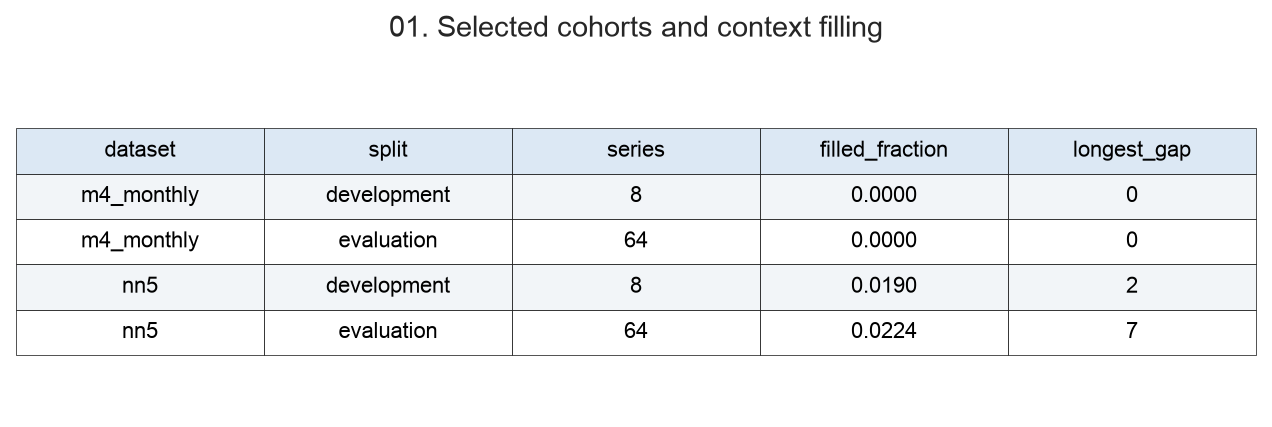

In [8]:
members, inputs, eligibility = prepare_data(write=CFG.mode == "prepare")
cohort = pd.DataFrame(members)
display(cohort.groupby(["dataset", "split"]).agg(series=("key", "size"), filled_fraction=("filled_fraction", "mean"), longest_gap=("longest_fill_run", "max")))
assets = begin_assets() if CFG.mode == "replay" else []
if CFG.mode == "replay":
    cohort_summary = cohort.groupby(["dataset", "split"], as_index=False).agg(series=("key", "size"), filled_fraction=("filled_fraction", "mean"), longest_gap=("longest_fill_run", "max"))
    export_table(cohort_summary, 1, "01. Selected cohorts and context filling", "Data and frozen forecasts", "data/cohort.json")

Table 01 confirms the fixed cohort sizes and NN5 fill rates; every method sees the identical filled contexts and cached quantiles.

# Six editors across the explore–exploit spectrum

- **Zero-query anchors:** *Seasonal naive* repeats the last observed seasonal cycle; *Frozen median* uses Chronos-2's unedited 0.50 quantile.
- **Best-of-N quantile:** constructs $B$ interpolated curves inside `[0.01, 0.99]` (snapping the nearest submedian level to `0.5` for even $B$) and picks the earliest highest score.
- **Random search & Direct CEM:** perturb the median in raw horizon space; Direct CEM refits a diagonal Gaussian from the top 20% elites each round.
- **CEM + prior:** our key control—uses DEFT's exact exploit/explore split (`16` quantile-pool calls, then `4 x 4` raw-horizon CEM calls at $B=32$).
- **DEFT & Pool only:** split `y = T + S` via an autocorrelation-selected centered moving average. At $B=32$, DEFT spends `16` seed calls (`1` median + `15` balanced `T_i + S_j` pairs), max-pools scores to components, and runs four `4`-call refinement rounds; *Pool only* spends all $B$ calls on the initial recombination grid.

# Head-to-head at matched budgets

Crossing `128` evaluation series × `6` editors × `3` budgets (`8, 32, 128`) × `3` seeds × `2` feedback modes produces **13,824 trials and 774,144 counted trajectory queries** (plus a separate `8,064`-query development pilot). Next, we verify every trial trace offline and summarize the primary `B=32`, `rating5` contrast.


In [9]:
run_dir = CFG.root / "evidence" / CFG.run_id
results = pd.read_csv(run_dir / "results.csv", float_precision="round_trip")
evaluation_members = [m for m in members if m["split"] == "evaluation"]
audited_calls = audit_trials(results, evaluation_members, inputs)
anchors = anchor_results(evaluation_members, inputs)
anchors.to_csv(CFG.root / "anchor-metrics.csv", index=False, float_format="%.17g")
averages, series_means, primary_pairs, summary = summarize(results)
assert audited_calls == summary["calls"]
print(json.dumps(summary, indent=2))

/Users/kbanachewicz/Documents/banan-lab/papers/deft-expert-guided-forecast-editing/validation/fresh-kernel-20261120T091941915552/tmp/ipykernel_130/239321282.py:2: Pandas4Warning: The 'float_precision' argument is deprecated. Use the default float precision instead.
  results = pd.read_csv(run_dir / "results.csv", float_precision="round_trip")


{
  "primary_difference": 0.025432668721922094,
  "sensitivity_low": -0.013359025302739677,
  "sensitivity_high": 0.060732530614538774,
  "corpus_effects": {
    "m4_monthly": 0.05086533744384419,
    "nn5": 0.0
  },
  "signal": "inconclusive",
  "complete_design": true,
  "planned_series_n": 128,
  "primary_available_series_n": 128,
  "trial_n": 13824,
  "attempted_trials": 13824,
  "complete_trials": 13824,
  "failed_trials": 0,
  "unattempted_trials": 0,
  "backbone_failed_series": 0,
  "calls": 774144
}


All `13,824` evaluation trials and `774,144` queries replay identically with zero invalid proposals or failed runs. In the primary `B=32`, `rating5` setting, DEFT minus Best-of-N quantile is **`+0.02543` MASE** (`[−0.01336, +0.06073]`), leaving the headline result **inconclusive**.


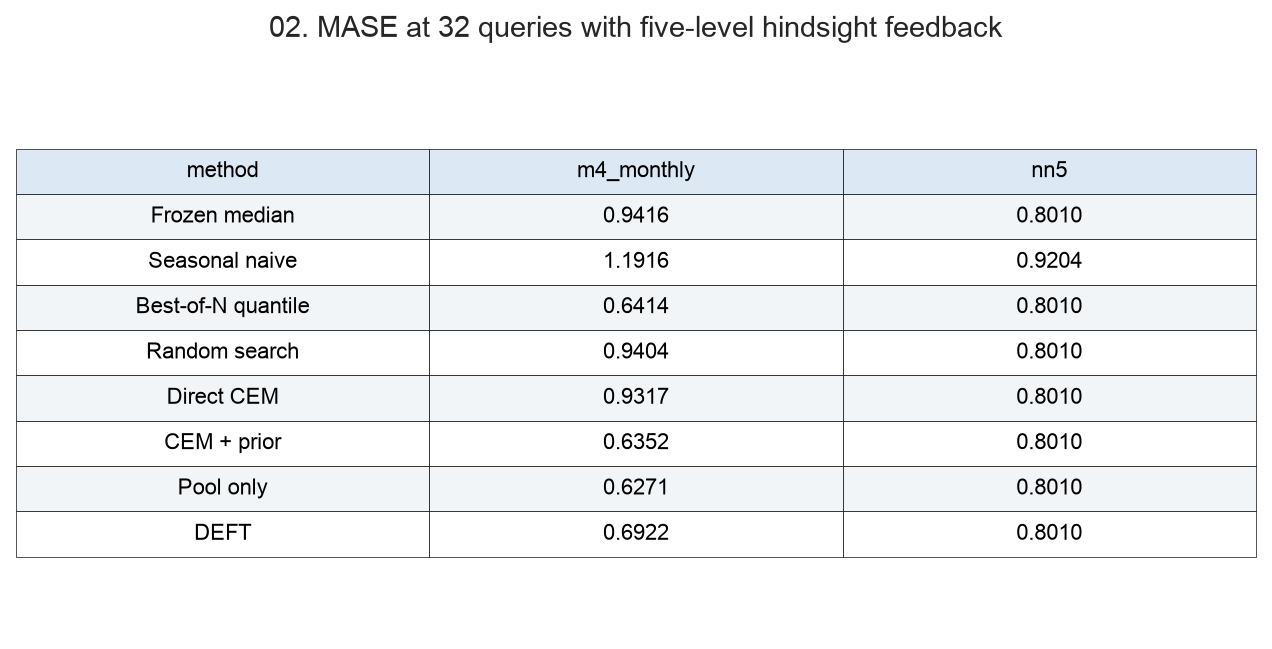

In [10]:
if summary["complete_design"]:
    render_primary_table(averages, anchors)

In Table 02 (`B=32`, `rating5`), Best-of-N quantile (`0.6414`), Pool only (`0.6271`), and CEM + prior (`0.6352`) all beat DEFT (`0.6922`) on M4 monthly, while every editor ties the frozen median (`0.8010`) on NN5.


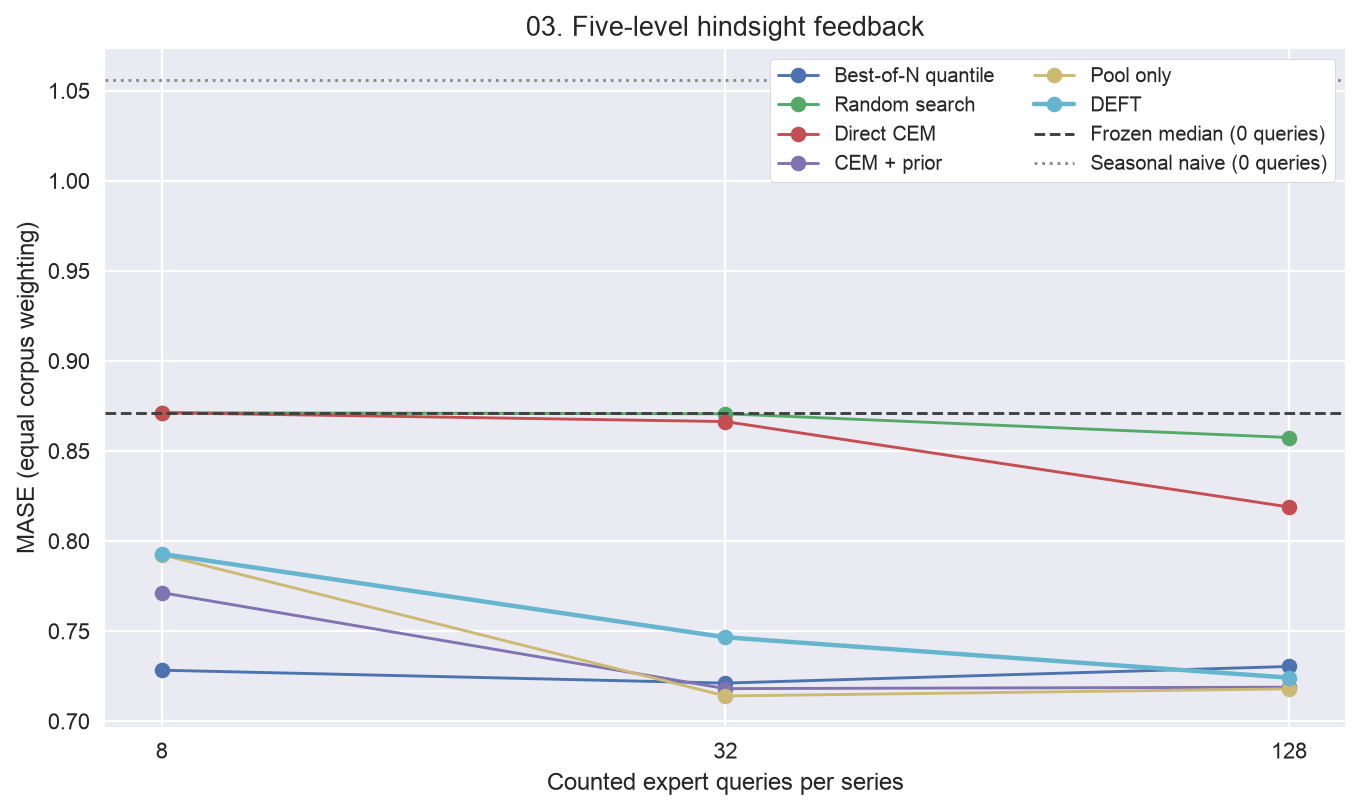

In [11]:
if summary["complete_design"]:
    render_budget_curve(averages, anchors, 3, "rating5")

Under `rating5` across budgets (Graph 03), DEFT catches Best-of-N quantile by `B=128` (`0.7242` vs. `0.7304`), though Pool only (`0.7180`) and CEM + prior (`0.7189`) remain slightly ahead.


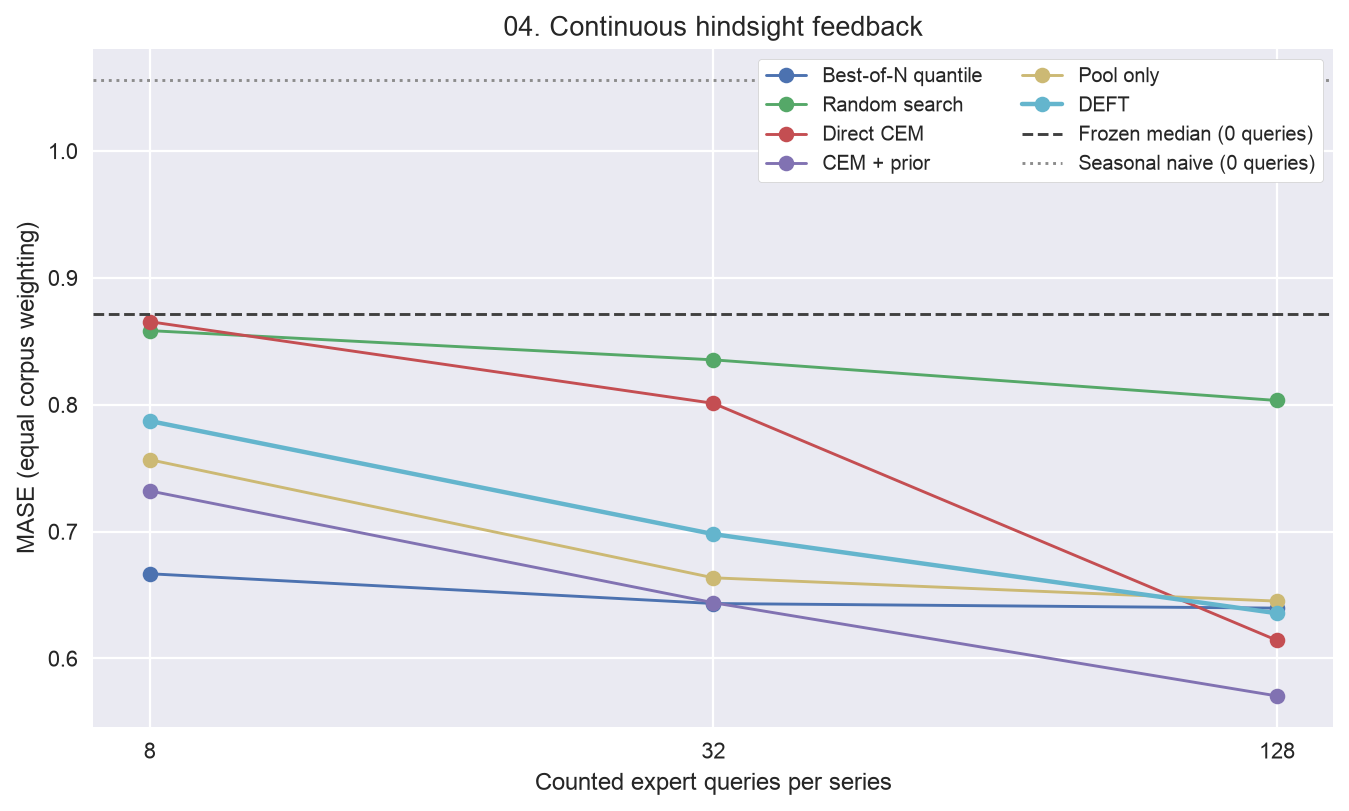

In [12]:
if summary["complete_design"]:
    render_budget_curve(averages, anchors, 4, "continuous")

Removing coarse quantization with continuous `-MSE` feedback (Graph 04) lets DEFT edge Best-of-N quantile at `B=128` (`0.6356` vs. `0.6397`), **while `CEM + prior` pulls far ahead to `0.5705`** (and even unseeded `Direct CEM` reaches `0.6143`).


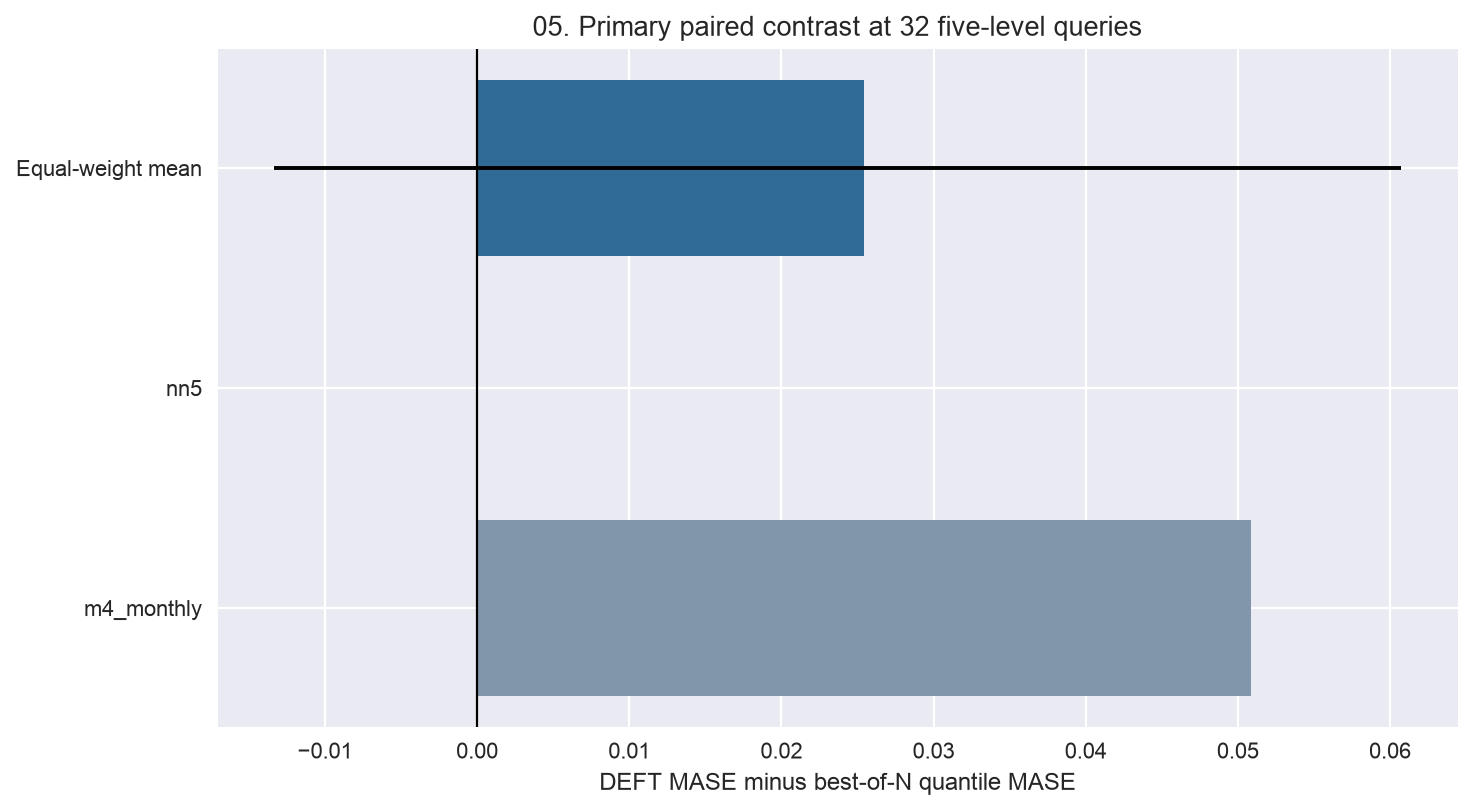

In [13]:
if summary["complete_design"]:
    render_primary_contrast(summary)

Graph 05 summarizes the primary `B=32`, `rating5` contrast: an M4 edge for quantile selection, a flat tie on NN5, and an aggregate sensitivity interval spanning zero.

# Why DEFT stalled: traces, conventions, and collapsed spread

Rather than stopping at an inconclusive table, the diagnostic outputs below—paired with a follow-up audit of the saved traces, implementation conventions, and proposal-scale dynamics—pinpoint what actually happened inside the search.

## Coarse plateaus hid real gains on NN5


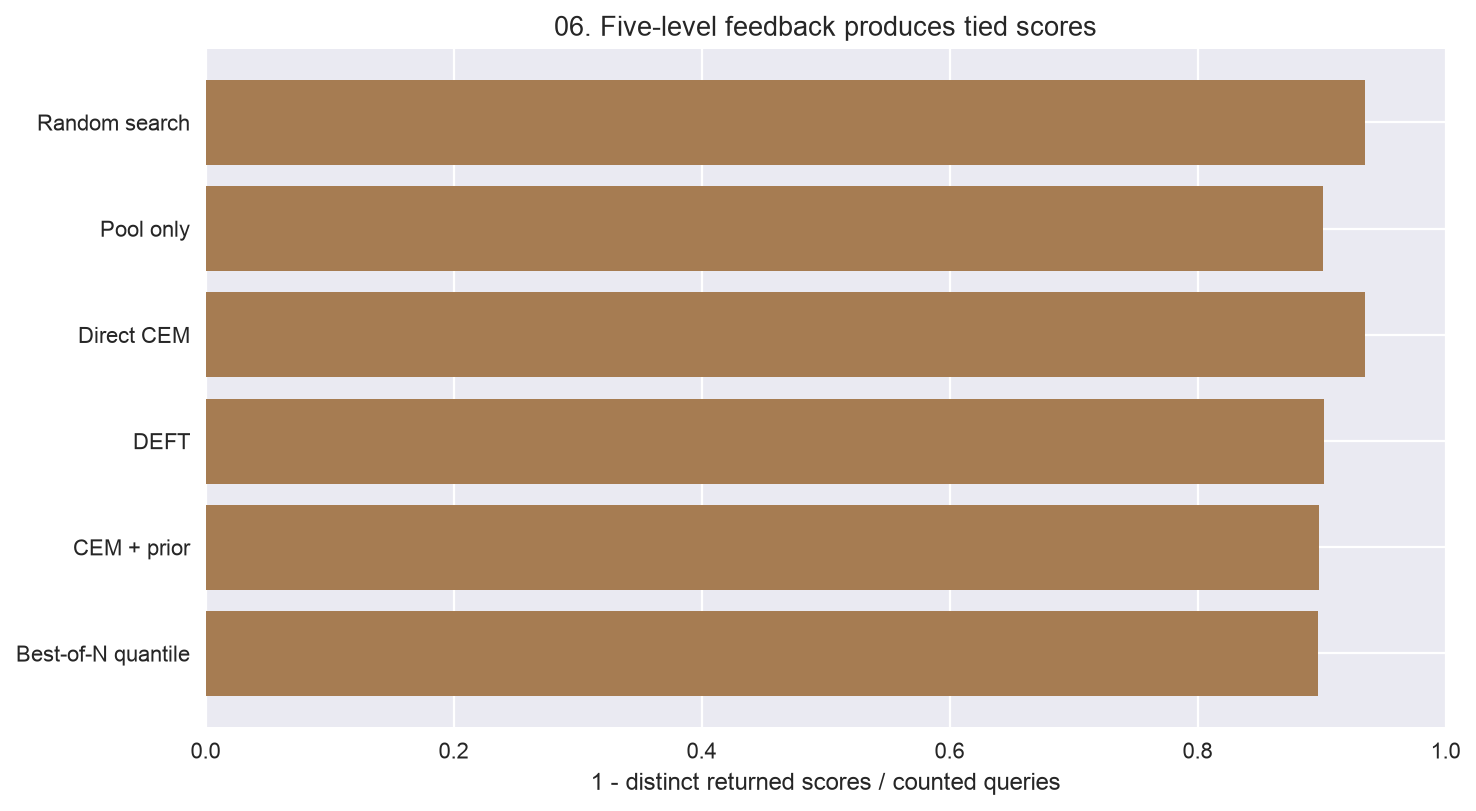

In [14]:
if summary["complete_design"]:
    render_feedback_ties(averages)

Graph 06 shows `~90%` score repetition across all editors under `rating5` at `B=32`, and **all 1,152 NN5 trials** kept candidate `0` (the median).

Yet the [retained-trace audit](followup-options-1-2/option1-findings.md) reveals that editors were still finding better trajectories underneath those tied scores: on NN5, **138 of 192 DEFT trials (`71.9%`)** and **177 of 192 Best-of-N quantile trials (`92.2%`)** queried at least one lower-MSE curve (averaging `7.87%` and `8.50%` best MSE cuts). None reached the 40% reduction needed to move from rating `3` to `4`. Even under continuous `B=128`, optimizing MSE worsened MAE/MASE in `7/192` M4 and `31/192` NN5 DEFT trials.


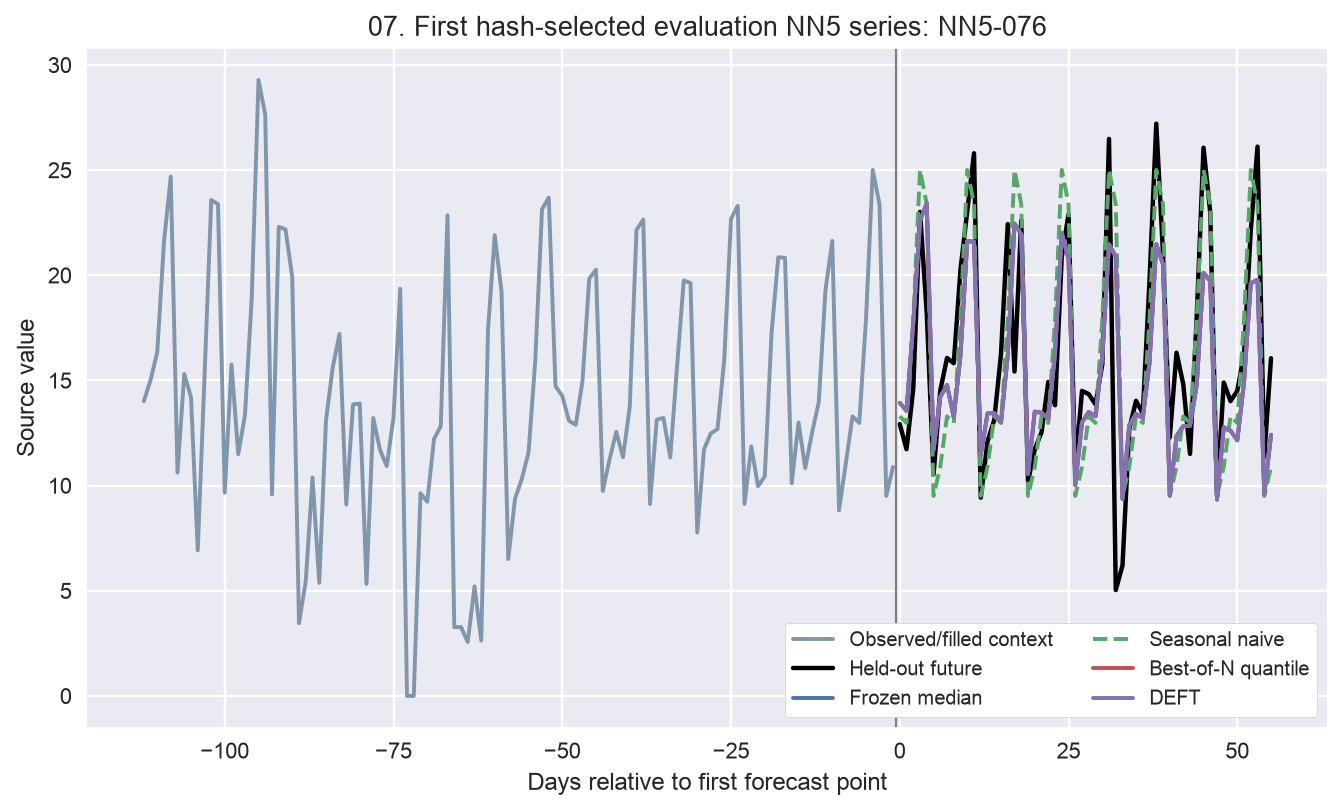

In [15]:
if summary["complete_design"]:
    example = min((m for m in evaluation_members if m["dataset"]=="nn5"),key=lambda m:m["rank"])
    render_forecast_example(example, inputs, run_dir)

Graph 07 makes that plateau concrete on `NN5-076` (selected by hash rank): after 32 queries, the median, quantile selection, and DEFT trajectories sit right on top of each other.


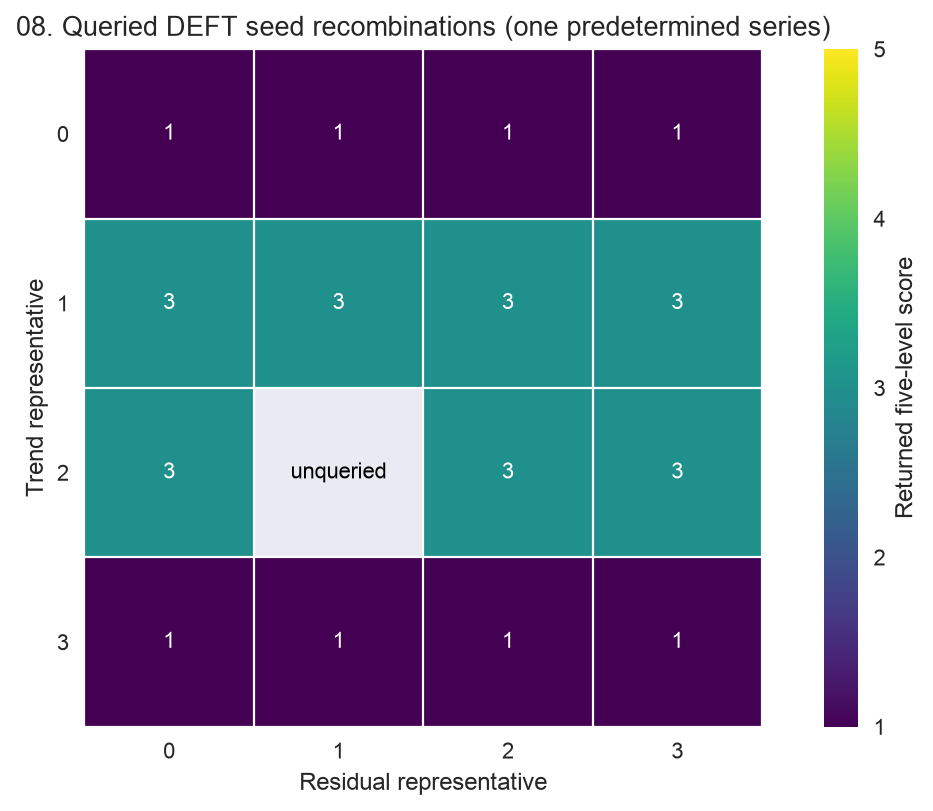

In [16]:
if summary["complete_design"]:
    render_seed_grid(example, run_dir)

Graph 08 shows DEFT's `15` scored `T_i + S_j` recombinations for `NN5-076` (with call `16` spent on the standalone median); none clears the median's score of `3`.


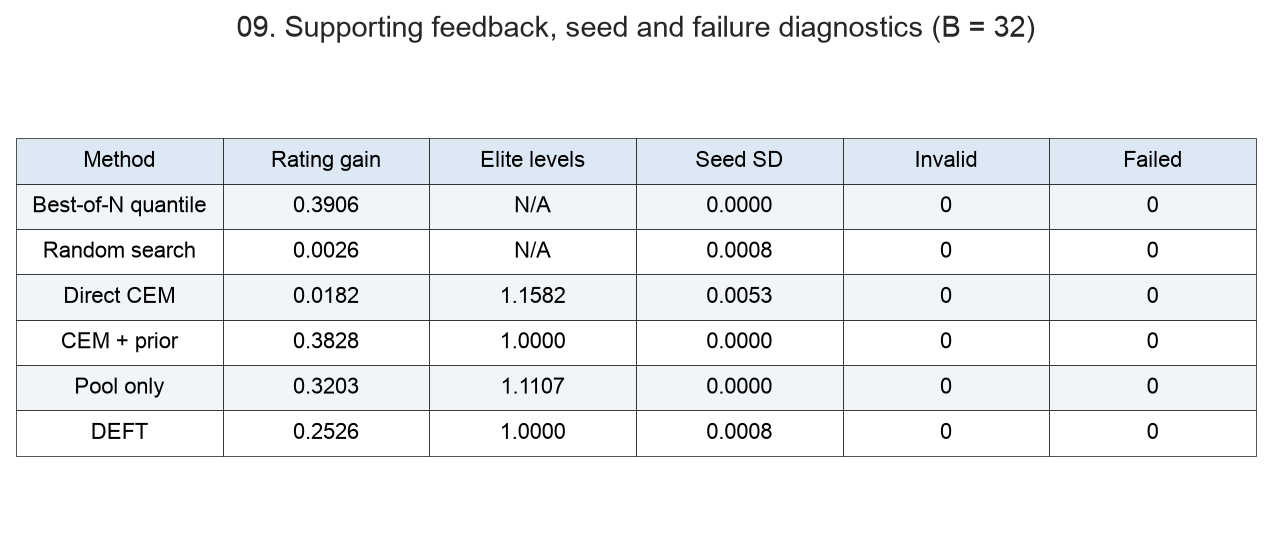

In [17]:
if summary["complete_design"]:
    render_diagnostics(results)

Table 09 confirms the bottleneck numerically: at `B=32`, both DEFT and CEM + prior see an average of `1.0` distinct elite score level, with zero invalid proposals or failed trials.


In [18]:
if summary["complete_design"]:
    save_original_timing(members, results)
    win_rows=[]
    for (dataset,mode,budget),part in series_means.groupby(["dataset","mode","budget"]):
        paired=part.pivot(index="key",columns="method",values="mase")
        reference=paired["best_quantile"]
        for method in CFG.methods:
            difference=paired[method]-reference
            win_rows.append({"dataset":dataset,"mode":mode,"budget":int(budget),"method":method,"reference":"best_quantile",
                             "series_n":len(paired),"wins":int((difference<0).sum()),"ties":int((difference==0).sum()),
                             "losses":int((difference>0).sum()),"relative_mean_mase":float(paired[method].mean()/reference.mean())})
    pd.DataFrame(win_rows).to_csv(CFG.root/"secondary-statistics.csv",index=False,float_format="%.17g")
else:
    print("Incomplete design: no primary interval or publication result plots; denominators retained.")
write_json(CFG.root / "graphs/manifest.json", assets)
write_json(CFG.root / "results-summary.json", summary)
averages.to_csv(CFG.root / "metrics.csv", index=False, float_format="%.17g")
write_json(CFG.root / "replay-validation.json", {"status": "passed" if summary["complete_design"] else "incomplete", "audited_calls": audited_calls,
           "trial_n": len(results), "mode": CFG.mode, "export_timestamp": CFG.execution_timestamp.isoformat(),
           "inference_run_id": CFG.run_id, "checks": check_record, "summary": summary})

## Checking the implementation conventions

Before modifying the optimizer, we tested five local choices where the paper's pseudocode leaves room for interpretation—running **2,132,352** new simulated queries on the cached Chronos-2 outputs ([fidelity.py](followup-options-1-2/fidelity.py), [option2-findings.md](followup-options-1-2/option2-findings.md)):

- **Full recombination-only seed scan:** spending all 16 seed calls on `T_i + S_j` pairs without a counted median anchor (reusing the 128 cached median-loss calibration references) *worsened* DEFT's gap from `+0.02543` to **`+0.09445` MASE** (`NN5` DEFT rose from `0.80097` to `0.90519`) because coarse ties locked in worse initial pairs.
- **Narrower `0.10–0.90` grid:** flipped the primary point estimate to **`−0.01544`**, though its sensitivity range **`[−0.03774, +0.00424]`** still spanned zero—and it did so largely by *weakening* Best-of-N quantile on M4 (`0.64137` → `0.69811`) while DEFT improved (`0.69223` → `0.66723`).
- **Symmetry, padding, and elite rounding:** duplicating `0.5` (`+0.03064`), reversing even-window padding (`+0.02110`), and nearest elite rounding (`+0.02543`) left the primary inconclusive verdict unchanged.

## Fixing the 1% scale collapse—and what changed

The trace audit also exposed a concrete numerical collapse at `B=32`: because DEFT and CEM + prior keep only **1 elite** per refinement round, the empirical elite standard deviation is `0`, clipping median proposal scales to **1% of their round-1 dispersion** for rounds 2–4. (`B=8` has only one refinement round, serving as an exact control.)

We tested exponential standard-deviation smoothing across DEFT, CEM + prior, and Direct CEM (`757,376` new queries: `7,808` dev + `749,568` eval; [editor.py](followup-option3-variance-smoothing/editor.py), [findings.md](followup-option3-variance-smoothing/findings.md)):

`sigma_next = max(alpha * sigma_current + (1 − alpha) * sigma_elites, original_floor)`

With `alpha=0.5`, DEFT's median proposal-scale ratios stayed open at **`1, 0.5, 0.25, 0.125`** across rounds 1–4 (instead of `1, 0.01, 0.01, 0.01`), and every primary candidate archive changed. **Yet all 384 primary DEFT trials per smoothing policy (`alpha=0.5` and stress `alpha=0.9`) returned the exact same forecast** as the unsmoothed run (`383` from the seed stage, `1` from the unsmoothed first refinement batch), leaving mean DEFT MASE at **`0.746602`**.

<!-- TABLE 10: publication-revision-20261121/graphs/table_10_2111.png -->
![B32 Rating-5 and B128 continuous MASE for DEFT, CEM with prior and Direct CEM under the original refit and two smoothing policies.](publication-revision-20261121/graphs/table_10_2111.png)

*10. Original and smoothed refinement policies: mean MASE across the two fixed cohorts.*

Meanwhile, the matched raw-CEM controls in Table 10 ([contrasts.csv](followup-option3-variance-smoothing/contrasts.csv)) show mixed effects: at `B=32`, `rating5` (`alpha=0.5`), CEM + prior (`0.718105` → `0.709294`) and Direct CEM (`0.866354` → `0.863328`) improve on M4 while NN5 stays tied at `0`; Direct CEM also improves across both corpora at `B=8` continuous (`0.865453` → `0.851945`). Yet at `B=128` continuous, keeping spread wide *hurts* convergence for CEM + prior (`0.570453` → `0.582887` at `alpha=0.5`, `0.601769` at `0.9`) and nudges DEFT up (`0.635633` → `0.637711`).

# What we learned

1. **Strong quantile selection is a formidable baseline on Chronos-2.** Echoing the paper's own Chronos results, scoring well-calibrated native quantiles—or seeding raw CEM with them—already captures most of what 32 queries can buy.
2. **Coarse rating plateaus dominate search geometry.** When moving off the median requires a 40% MSE drop, `72%` of DEFT's NN5 runs and `92%` of quantile selection's runs find better trajectories that five-level ties discard.
3. **Fixing a broken optimizer mechanism doesn't guarantee a better forecast.** The 1% single-elite collapse was real, and smoothing preserved search spread; yet under coarse feedback no later round beat the seed pool, and under generous continuous feedback wider spread slowed convergence.
4. **Proxy objectives can pull against accuracy metrics.** Optimizing MSE while reporting MASE degraded MAE/MASE in ~16% of NN5 continuous `B=128` runs, echoing the paper's molecular-dynamics trade-off.
5. **Implementation audits catch misleading wins.** Narrowing the quantile grid made DEFT look better mainly by hobbling Best-of-N quantile, while removing the counted median anchor exposed how fragile recombination becomes without a protected incumbent.

# Scope and limits

This is a local Chronos-2 adaptation on 64 M4 monthly and 64 NN5 daily series at one tail origin per series, not a full reproduction of the paper's 78-dataset, multi-backbone benchmark or physics experiment. Pretraining overlap is unresolved, NN5 results depend on causal forward-filling, the hindsight oracle supplies future-MSE ratings unavailable at forecast time, paired bootstrap intervals assume independent series, and all follow-up checks were designed after inspecting this cohort. Offline replay verifies exact candidate reconstruction and metrics from retained archives without new model inference.
